# 04 - Attention (M2) and beam search

**Goal of this notebook.** Remove the main weakness of the models M1 and M1b, the bottleneck between the encoder and the decoder, with
an **attention mechanism**. Then compare M2 (attention) with M1b (the same model without attention), and look at the second way of
generating an output, **beam search**.



Files written by this notebook:

| File | Role |
|---|---|
| `src/t2s/models/attention.py` | the attention layer, the decoder that uses it, the model M2, and decoding that returns the attention weights |
| `src/t2s/decoding/beam.py` | beam search |
| `configs/m2.yaml` | the settings of M2 |

Tools from earlier notebooks that are used here:

| Tool | What it does | Where it is explained |
|---|---|---|
| `Seq2Seq` (`forward`, `_decoder_state`), `Encoder`, `Decoder` | the model without attention, which M2 extends | notebook 03, sections 3 to 5 |
| `train`, `load_checkpoint`, `build_model` | the training loop; `build_model` picks the model from `type` in the config | notebook 03, section 8 |
| `greedy_decode`, `decode_examples` | greedy decoding | notebook 03, sections 6 and 7 |
| `score`, `SqliteExecutor` | exact match and execution accuracy | notebook 03, section 1; notebook 01, section 6 |
| `build_vocab`, `encode_example`, `collate`, `source_tokens`, `PlainCodec` | text to ids, batches, the codec | notebook 02 |

## Setup



In [1]:
import json, os, sys
from pathlib import Path

NOTEBOOK_NUMBER = 4

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT = Path("/content/drive/MyDrive/text2sql")
    CODE = "/content/code"                                      # where the notebooks write their code
    DATA_ROOT = "/content/data"                                 # the dataset (downloaded in each session)
    CKPT_DIR = "/content/drive/MyDrive/text2sql_checkpoints"    # the saved models
else:
    PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    CODE, DATA_ROOT, CKPT_DIR = str(PROJECT / "code"), str(PROJECT / "data"), str(PROJECT / "checkpoints")
os.chdir(PROJECT)   # the results are saved in the folder "results" of the project
os.makedirs(CKPT_DIR, exist_ok=True)


def rebuild_code(before):
    """Write again the code files of the notebooks 01 ... before-1 (their writefile cells)."""
    for path in sorted((PROJECT / "notebooks").glob("[0-9][0-9]_*.ipynb")):
        if int(path.name[:2]) >= before:
            continue
        for cell in json.loads(path.read_text())["cells"]:
            source = "".join(cell["source"])
            if cell["cell_type"] != "code" or not source.startswith("%%writefile"):
                continue
            first_line, _, body = source.partition("\n")
            words = first_line.split()
            target = Path(words[-1].replace("{CODE}", CODE))
            target.parent.mkdir(parents=True, exist_ok=True)
            with open(target, "a" if words[1] == "-a" else "w") as f:
                f.write(body if body.endswith("\n") else body + "\n")


for folder in ["src/t2s/data", "src/t2s/models", "src/t2s/decoding", "src/t2s/eval", "scripts", "configs"]:
    os.makedirs(f"{CODE}/{folder}", exist_ok=True)
rebuild_code(NOTEBOOK_NUMBER)
for package in ["src/t2s", "src/t2s/data", "src/t2s/models", "src/t2s/decoding", "src/t2s/eval"]:
    Path(f"{CODE}/{package}/__init__.py").touch()
sys.path.insert(0, f"{CODE}/src")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import json
from pathlib import Path
import torch
from t2s.data.download import download_wikisql
from t2s.data.wikisql import load_split, db_path
from t2s.eval.executor import SqliteExecutor

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

data_dir = download_wikisql(DATA_ROOT)
splits = {name: load_split(data_dir, name) for name in ["train", "dev"]}
dev_executor = SqliteExecutor(db_path(data_dir, "dev"))
Path("results/phase4_attention").mkdir(parents=True, exist_ok=True)

device: cuda


## 1. The problem that attention solves

In M1 and M1b the decoder starts from **one vector**: the final state of the encoder (256 numbers). Everything the decoder will need
has to fit in it: the whole question, every column name, every value. An input has 32 tokens on average and up to 190. Exact words
such as `tunisia` or `fuel propulsion` are easily blurred in such a summary, and the longer the input, the worse it gets.

**The idea of attention.** Do not force everything through one vector. Keep **all** the encoder states (one per input position), and at
each step let the decoder *look back* at them and decide which ones matter *now*. When it writes the value `tunisia`, it should look at
the input word `tunisia`.

At each decoding step, with `s` the state of the decoder and `h_1 ... h_T` the encoder states:

1. **Scores.** Compare `s` with each `h_i`: `score_i = v . tanh(W_h h_i + W_s s)`. A high score means "position `i` is useful now".
2. **Weights.** `weights = softmax(scores)`. They are positive and add up to 1. The padding positions get a score of `-inf`, so their
   weight is exactly 0.
3. **Context.** `context = sum_i weights_i * h_i`: a weighted average of the encoder states, dominated by the positions that matter.
4. **Use.** The context and `s` are joined: `attentional state = tanh(W_c [s ; context])`. The scores of the next token are computed from it.

The weights `W_h`, `W_s`, `v` and `W_c` are learned together with the rest of the model.

## 2. The attention code

**The description and the imports.** The equations of the introduction are in the docstring. This file reuses `Decoder` and `Seq2Seq` of
notebook 03.

In [3]:
%%writefile {CODE}/src/t2s/models/attention.py
"""Attention: the decoder looks back at all the encoder states at every step.

Without attention, everything the decoder knows about the input is the final state of the
encoder. With attention, at each output step the decoder computes how much each input
position matters now, and reads a weighted average of the encoder states:

    score_i   = v . tanh(W_h h_i + W_s s_t)       h_i: encoder state of position i
                                                  s_t: decoder state at step t
    weights   = softmax(scores)                   positive, sum to 1 (padding gets 0)
    context   = sum_i weights_i * h_i             the weighted average
    attentional state = tanh(W_c [s_t ; context]) used to score the next token

This file has the attention layer, a decoder that uses it, and the model that puts them
together (`AttentionSeq2Seq`, model M2). It reuses the encoder, the decoder parts and the
training code of the models without attention.
"""

import torch
from torch import nn

from t2s.models.decoder import Decoder
from t2s.models.seq2seq import Seq2Seq




Overwriting /content/code/src/t2s/models/attention.py


**`AdditiveAttention.__init__`** has three small linear layers: `w_h` is applied to the encoder states, `w_s` to the decoder state, and
`v` turns a vector into one number (the score). Because the formula *adds* `W_h h_i` and `W_s s`, this is called *additive* attention
(Bahdanau et al., 2015).

In [4]:
%%writefile -a {CODE}/src/t2s/models/attention.py
class AdditiveAttention(nn.Module):
    def __init__(self, enc_dim: int, dec_dim: int, attn_dim: int):
        super().__init__()
        self.w_h = nn.Linear(enc_dim, attn_dim, bias=False)  # applied to the encoder states
        self.w_s = nn.Linear(dec_dim, attn_dim)  # applied to the decoder state
        self.v = nn.Linear(attn_dim, 1, bias=False)  # turns a vector into one score



Appending to /content/code/src/t2s/models/attention.py


**`keys`** computes `W_h h_i` for every position. It does not depend on the decoding step, so it is computed **once** for each input and
not at every step.

In [5]:
%%writefile -a {CODE}/src/t2s/models/attention.py
    def keys(self, enc_states: torch.Tensor) -> torch.Tensor:
        """W_h h_i for every position. It does not depend on the step, so it is computed once."""
        return self.w_h(enc_states)



Appending to /content/code/src/t2s/models/attention.py


**`forward`** computes one attention step for a batch:

1. the score of every position: `v(tanh(keys + W_s query))`;
2. `masked_fill(~mask, -inf)`: the padding positions get `-inf`, so the softmax gives them a weight of exactly 0;
3. `softmax` gives the weights, which add up to 1;
4. `bmm` (batch matrix product) computes the weighted average of the encoder states: the context.

It returns the context and the weights.

In [6]:
%%writefile -a {CODE}/src/t2s/models/attention.py
    def forward(
        self,
        query: torch.Tensor,
        enc_states: torch.Tensor,
        keys: torch.Tensor,
        mask: torch.Tensor,
    ) -> tuple[torch.Tensor, torch.Tensor]:
        """query: decoder state (B, H); enc_states: (B, T, E); keys: (B, T, A); mask: (B, T).

        Returns the context vector (B, E) and the attention weights (B, T).
        """
        scores = self.v(torch.tanh(keys + self.w_s(query).unsqueeze(1))).squeeze(-1)  # (B, T)
        scores = scores.masked_fill(~mask, float("-inf"))  # padding positions cannot be chosen
        weights = torch.softmax(scores, dim=-1)
        context = torch.bmm(weights.unsqueeze(1), enc_states).squeeze(1)  # (B, E)
        return context, weights




Appending to /content/code/src/t2s/models/attention.py


**`AttentionDecoder.__init__`.** It is the decoder of notebook 03 (embedding, LSTM layers, output layer) plus the attention layer and
`combine` (the matrix `W_c`). `last_weights` keeps the attention weights of the last step, for the heatmaps.

In [7]:
%%writefile -a {CODE}/src/t2s/models/attention.py
class AttentionDecoder(Decoder):
    def __init__(
        self,
        vocab_size: int,
        emb_dim: int,
        hidden: int,
        num_layers: int,
        dropout: float,
        pad_id: int,
        enc_dim: int,
    ):
        super().__init__(vocab_size, emb_dim, hidden, num_layers, dropout, pad_id)
        self.attention = AdditiveAttention(enc_dim, hidden, hidden)
        self.combine = nn.Linear(enc_dim + hidden, hidden)  # W_c
        self.last_weights = None  # attention weights of the last step, kept for the heatmaps



Appending to /content/code/src/t2s/models/attention.py


**`AttentionDecoder.step`** is one decoding step.

1. The LSTM layers run exactly as in the decoder without attention.
2. `decoder_state` is the hidden state of the last layer; it is the **query** of the attention.
3. The attention gives the context and the weights.
4. The context and the decoder state are joined and passed through `combine` and `tanh`: the *attentional state*.
5. The output layer turns the attentional state into the scores of the next token.

`memory` holds what attention needs: the encoder states, their keys, and the mask.

In [8]:
%%writefile -a {CODE}/src/t2s/models/attention.py
    def step(self, token, state, memory):
        """One decoding step with attention.

        memory: (encoder states, their keys, mask of the real positions), made once per input.
        """
        enc_states, keys, mask = memory
        h, c = state
        x = self.dropout(self.embedding(token))
        new_h, new_c = [], []
        for layer, cell in enumerate(self.cells):
            h_layer, c_layer = cell(x, (h[layer], c[layer]))
            new_h.append(h_layer)
            new_c.append(c_layer)
            x = self.dropout(h_layer)

        decoder_state = new_h[-1]  # s_t, the hidden state of the last layer
        context, weights = self.attention(decoder_state, enc_states, keys, mask)
        attentional = torch.tanh(self.combine(torch.cat([decoder_state, context], dim=-1)))
        self.last_weights = weights
        return self.out(self.dropout(attentional)), (torch.stack(new_h), torch.stack(new_c))




Appending to /content/code/src/t2s/models/attention.py


**`AttentionSeq2Seq`** is the model M2. It **inherits** from `Seq2Seq` of notebook 03: the training loop `forward` and the way the
starting state of the decoder is built are exactly the same. Only the decoder is replaced by the one with attention.

In [9]:
%%writefile -a {CODE}/src/t2s/models/attention.py
class AttentionSeq2Seq(Seq2Seq):
    """Model M2: the encoder-decoder with attention. `forward` is the one of `Seq2Seq`."""

    def __init__(
        self,
        vocab_size: int,
        pad_id: int,
        emb_dim: int = 256,
        hidden: int = 256,
        num_layers: int = 1,
        bidirectional: bool = True,
        dropout: float = 0.3,
    ):
        super().__init__(vocab_size, pad_id, emb_dim, hidden, num_layers, bidirectional, dropout)
        self.decoder = AttentionDecoder(
            vocab_size, emb_dim, hidden, num_layers, dropout, pad_id, enc_dim=self.encoder.out_dim
        )



Appending to /content/code/src/t2s/models/attention.py


**`init_decode`** reads the input like before, and also prepares the `memory`: the encoder states of **all** the positions, their keys, and
a mask (`True` on the real positions, `False` on the padding).

In [10]:
%%writefile -a {CODE}/src/t2s/models/attention.py
    def init_decode(self, src: torch.Tensor, src_len: torch.Tensor):
        """Read the input. The memory holds what attention needs at every step."""
        enc_states, enc_state = self.encoder(src, src_len)
        positions = torch.arange(src.size(1), device=src.device)
        mask = positions[None, :] < src_len.to(src.device)[:, None]  # True on real positions
        keys = self.decoder.attention.keys(enc_states)
        return self._decoder_state(enc_state), (enc_states, keys, mask)



Appending to /content/code/src/t2s/models/attention.py


**`step`** passes the memory to the decoder.

In [11]:
%%writefile -a {CODE}/src/t2s/models/attention.py
    def step(self, token, state, memory):
        return self.decoder.step(token, state, memory)




Appending to /content/code/src/t2s/models/attention.py


**`decode_with_attention`** is greedy decoding that also returns the attention weights of every step. I use it to draw the heatmaps.

In [12]:
%%writefile -a {CODE}/src/t2s/models/attention.py
@torch.no_grad()
def decode_with_attention(model, src, src_len, sos_id, eos_id, max_len: int = 64):
    """Greedy decoding that also returns the attention weights of every step.

    Returns, for each input, the output ids (without <eos>) and a (steps, T) matrix of weights.
    """
    model.eval()
    state, memory = model.init_decode(src, src_len)
    token = torch.full((src.size(0),), sos_id, dtype=torch.long, device=src.device)
    tokens, weights = [], []
    for _ in range(max_len):
        scores, state = model.step(token, state, memory)
        token = scores.argmax(dim=-1)
        tokens.append(token)
        weights.append(model.decoder.last_weights)
        if (torch.stack(tokens).eq(eos_id).any(dim=0)).all():
            break

    tokens = torch.stack(tokens, dim=1)  # (B, steps)
    weights = torch.stack(weights, dim=1)  # (B, steps, T)
    results = []
    for ids, w in zip(tokens.tolist(), weights):
        cut = ids.index(eos_id) + 1 if eos_id in ids else len(ids)  # keep the step that wrote <eos>
        results.append((ids[: cut - 1] if eos_id in ids else ids, w[:cut].cpu()))
    return results


Appending to /content/code/src/t2s/models/attention.py


### 2.1 Attention on a small example

Before using it in a model, I run the attention layer on random numbers, to see what it does: 2 inputs of 6 positions, where the second
input has only 3 real positions (the other 3 are padding).

In [13]:
from t2s.models.attention import AdditiveAttention

torch.manual_seed(0)
attention = AdditiveAttention(enc_dim=4, dec_dim=3, attn_dim=5)
enc_states = torch.randn(2, 6, 4)                     # 2 inputs, 6 positions, 4 numbers per position
lengths = torch.tensor([6, 3])                        # real length of each input
mask = torch.arange(6)[None, :] < lengths[:, None]    # True on real positions
query = torch.randn(2, 3)                             # the decoder state for each input

context, weights = attention(query, enc_states, attention.keys(enc_states), mask)
print("weights of input 1:", weights[0].detach().numpy().round(3), " sum =", round(weights[0].sum().item(), 4))
print("weights of input 2:", weights[1].detach().numpy().round(3), " sum =", round(weights[1].sum().item(), 4))
print("context vector shape:", tuple(context.shape))

weights of input 1: [0.125 0.15  0.158 0.239 0.149 0.179]  sum = 1.0
weights of input 2: [0.389 0.31  0.301 0.    0.    0.   ]  sum = 1.0
context vector shape: (2, 4)


**What I observe.** The weights are positive and add up to 1 for each input. For the second input, the three padding positions get a
weight of **exactly 0**, so the padding cannot disturb the result. The context has one vector (of the size of the encoder states) for each
input.

### 2.2 The model M2, and the same two checks as before

The first loss of a new model must be close to `ln(V)`, and the model must be able to memorize one batch (see notebook 03).

In [14]:
import math
import torch.nn.functional as F
from t2s.data.dataset import build_vocab, encode_example, collate
from t2s.models.seq2seq import Seq2Seq, count_parameters
from t2s.models.attention import AttentionSeq2Seq

vocab = build_vocab(splits["train"], min_freq=2)
encoded = [encode_example(e, vocab) for e in splits["train"][:64]]
batch = {k: v.to(device) for k, v in collate(encoded, vocab.pad_id).items()}

torch.manual_seed(0)
model = AttentionSeq2Seq(len(vocab), vocab.pad_id, emb_dim=256, hidden=256, bidirectional=True, dropout=0.0).to(device)
scores = model(batch["src"], batch["src_len"], batch["tgt_in"])
loss = F.cross_entropy(scores.reshape(-1, len(vocab)), batch["tgt_out"].reshape(-1), ignore_index=vocab.pad_id)

without = Seq2Seq(len(vocab), vocab.pad_id, emb_dim=256, hidden=256, bidirectional=True, dropout=0.0)
print(f"scores: {tuple(scores.shape)}")
print(f"expected first loss ln(V) = {math.log(len(vocab)):.2f}   measured = {loss.item():.2f}")
print(f"parameters: M1b {count_parameters(without):,}   M2 {count_parameters(model):,}   (attention adds {count_parameters(model) - count_parameters(without):,})")

optimizer = torch.optim.Adam(model.parameters(), lr=3e-3)
for step in range(151):
    scores = model(batch["src"], batch["src_len"], batch["tgt_in"])
    loss = F.cross_entropy(scores.reshape(-1, len(vocab)), batch["tgt_out"].reshape(-1), ignore_index=vocab.pad_id)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if step % 50 == 0:
        print(f"step {step:3d}  loss {loss.item():.3f}")

scores: (64, 25, 15962)
expected first loss ln(V) = 9.68   measured = 9.67
parameters: M1b 14,115,418   M2 14,509,402   (attention adds 393,984)
step   0  loss 9.666
step  50  loss 0.888
step 100  loss 0.028
step 150  loss 0.008


In [14]:
!grep -n "^class \|    def \|^def " {CODE}/src/t2s/models/attention.py

25:class AdditiveAttention(nn.Module):
26:    def __init__(self, enc_dim: int, dec_dim: int, attn_dim: int):
32:    def keys(self, enc_states: torch.Tensor) -> torch.Tensor:
36:    def forward(
54:class AttentionDecoder(Decoder):
55:    def __init__(
70:    def step(self, token, state, memory):
92:class AttentionSeq2Seq(Seq2Seq):
95:    def __init__(
110:    def init_decode(self, src: torch.Tensor, src_len: torch.Tensor):
119:def decode_with_attention(model, src, src_len, sos_id, eos_id, max_len: int = 64):


**What I observe.** The first loss is close to `ln(V)` (9.68), as it must be for a model that knows nothing. The model can memorize a
batch (the loss falls to nearly zero). Attention adds only about 0.4 million parameters to M1b (the small layers `W_h`, `W_s`, `v`, `W_c`),
so M2 and M1b have almost the same size: a difference in their results will not come from M2 being much bigger.

## 3. Training M2

The settings are the same as for M1b, except one line: `type: attention` tells `build_model` (notebook 03) to build `AttentionSeq2Seq`. The
comparison of M1b and M2 therefore changes **one thing**: attention.

**`configs/m2.yaml`:** the settings of M2 (see notebook 03, section 9, for the meaning of each one).

In [15]:
%%writefile {CODE}/configs/m2.yaml
# M2: like M1b (bidirectional encoder), with attention.
name: m2
seed: 0

data:
  min_freq: 2
  max_src_len: 128
  max_tgt_len: 64

model:
  type: attention
  emb_dim: 256
  hidden: 256
  num_layers: 1
  bidirectional: true
  dropout: 0.3

train:
  epochs: 25
  batch_size: 64
  lr: 0.001
  weight_decay: 0.0
  clip: 1.0
  teacher_forcing: 1.0
  patience: 4
  lr_patience: 1
  eval_subset: 1000


Writing /content/code/configs/m2.yaml


In [16]:
import yaml
from t2s.train import train

cfg_m2 = yaml.safe_load((Path(CODE) / "configs/m2.yaml").read_text())
result_m2 = train(cfg_m2, data_dir, results_dir="results", ckpt_dir=CKPT_DIR, resume=True)

m2: 14,509,402 parameters, vocabulary 15,962, 56,355 training examples, device cuda
epoch  1 | train loss 3.154 | dev loss 1.778 | dev token acc 0.681 | subset exact 0.015 | subset exec 0.030 | 67s *
epoch  2 | train loss 1.582 | dev loss 1.042 | dev token acc 0.796 | subset exact 0.094 | subset exec 0.118 | 65s *
epoch  3 | train loss 0.995 | dev loss 0.714 | dev token acc 0.856 | subset exact 0.186 | subset exec 0.206 | 68s *
epoch  4 | train loss 0.661 | dev loss 0.562 | dev token acc 0.886 | subset exact 0.237 | subset exec 0.265 | 71s *
epoch  5 | train loss 0.483 | dev loss 0.498 | dev token acc 0.897 | subset exact 0.253 | subset exec 0.281 | 70s *
epoch  6 | train loss 0.376 | dev loss 0.452 | dev token acc 0.907 | subset exact 0.292 | subset exec 0.318 | 70s *
epoch  7 | train loss 0.301 | dev loss 0.423 | dev token acc 0.914 | subset exact 0.286 | subset exec 0.312 | 70s *
epoch  8 | train loss 0.255 | dev loss 0.398 | dev token acc 0.918 | subset exact 0.293 | subset exec 0.

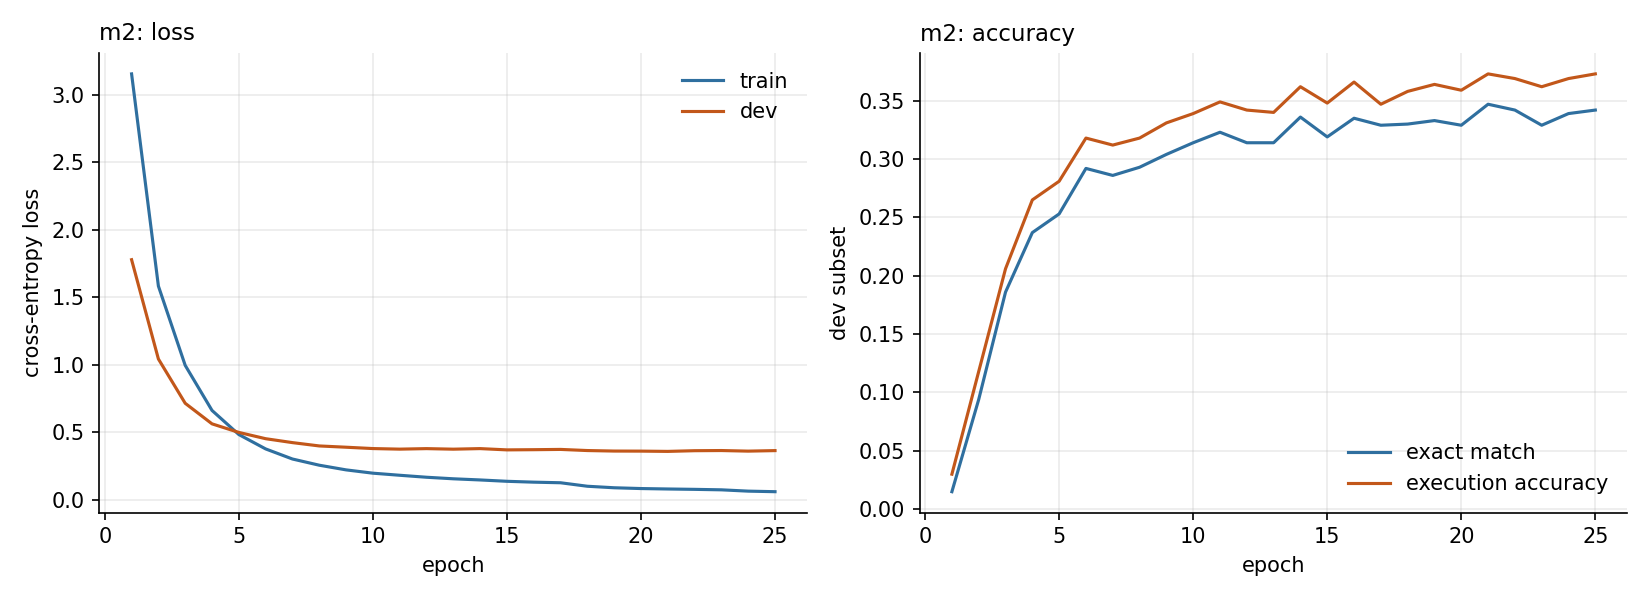

In [17]:
from IPython.display import Image
Image("results/m2/curves.png")

**What I observe.**

| | M0 | M1 | M1b | M2 |
|---|---|---|---|---|
| Parameters | 0 | 13.3 M | 14.1 M | 14.5 M |
| Exact match | 0.0% | 17.4% | 16.4% | **40.2%** |
| Execution accuracy | 0.01% | 22.3% | 21.1% | **44.9%** |
| Valid format | 100% | 72.4% | 69.9% | **87.4%** |

- **Attention is the most important improvement so far.** M2 has the same encoder as M1b and only 0.4 million more parameters (+2.8%), yet its exact match is 23.8 points higher (40.2% against 16.4%) and its execution accuracy 23.8 points higher (44.9% against 21.1%). Since M2 differs from M1b only by attention, the gain can be attributed to it. The difference is far larger than the uncertainty of the measure (about ±1 point on 8,421 questions).
- **Why it helps.** In M1 and M1b the decoder must write the whole query from one vector of 256 numbers. With attention, at each step the decoder looks at all the positions of the input and can locate the column name or the value it has to write. The token accuracy goes from about 80% to 93.5%, and the share of invalid outputs from 28 to 30% down to 12.6%.
- **What remains.** M2 is still limited by the words that are not in its vocabulary: a model that writes words from the vocabulary cannot exceed about 62% on dev (notebook 02), and M2 is at 40%. The 12.6% invalid outputs and the wrong values are the next target (the copy mechanism, notebook 05).

## 4. M2 against the models without attention

In [18]:
import pandas as pd

rows = []
for name in ["m0", "m1", "m1b", "m2"]:
    path = Path(f"results/{name}/metrics.json")
    if not path.exists():
        continue
    result = json.loads(path.read_text())
    dev = result["dev"]
    rows.append({
        "model": name,
        "parameters": f"{result['parameters']:,}",
        "exact match": round(dev["exact_match"], 4),
        "execution accuracy": round(dev["execution_accuracy"], 4),
        "valid format": round(dev["valid_format"], 4),
        "token accuracy": round(dev.get("token_accuracy", float("nan")), 4),
        "perplexity": round(dev.get("perplexity", float("nan")), 2),
        "best epoch": result.get("best_epoch", "-"),
    })
comparison = pd.DataFrame(rows).set_index("model")
comparison.to_csv("results/phase4_attention/comparison.csv")
comparison

,parameters,exact match,execution accuracy,valid format,token accuracy,perplexity,best epoch
model,,,,,,,
m0,0,0.0000,0.0001,1.0000,NaN,NaN,-
m1,"13,326,426",0.1744,0.2225,0.7239,0.7975,3.46,25
m1b,"14,115,418",0.1644,0.2107,0.6990,0.7913,3.64,24
m2,"14,509,402",0.4022,0.4486,0.8741,0.9352,1.43,21


- **Best epoch.** M2 reached its best dev loss at epoch 21 of 25, and the four last epochs brought no further gain, while M1 (epoch 25) and M1b (epoch 24) were still improving when the budget ended. So M2 trained to convergence, and the comparison does not favor it because of more training.

## 5. What does the attention look at?

The weights are a table: one row for each output token, one column for each input token. A dark cell means "when writing this output
token, the decoder looked at this input token". I draw it for three dev questions.

In [20]:
import matplotlib.pyplot as plt
from t2s.data.format import source_tokens
from t2s.models.attention import decode_with_attention
from t2s.train import load_checkpoint

model, codec, cfg = load_checkpoint(f"{CKPT_DIR}/m2/best.pt", device)
vocab = codec.vocab
shown = [ex for ex in splits["dev"][:100] if len(ex.query.conds) >= 1][:3]

for number, ex in enumerate(shown):
    encoded = codec.encode(ex)
    src = torch.tensor([encoded.src], device=device)
    src_len = torch.tensor([len(encoded.src)], device=device)
    (ids, weights), = decode_with_attention(model, src, src_len, vocab.sos_id, vocab.eos_id)
    inputs = source_tokens(ex.question, ex.header)[: len(encoded.src)]
    outputs = codec.decode(ids, encoded) + ["<eos>"]

    fig, ax = plt.subplots(figsize=(0.32 * len(inputs) + 2, 0.32 * len(outputs) + 1.5))
    ax.imshow(weights.numpy(), cmap="Blues", aspect="auto", vmin=0, vmax=1)
    ax.set_xticks(range(len(inputs)))
    ax.set_xticklabels(inputs, rotation=90, fontsize=8)
    ax.set_yticks(range(len(outputs)))
    ax.set_yticklabels(outputs, fontsize=8)
    ax.set_xlabel("input tokens")
    ax.set_ylabel("output tokens")
    ax.set_title(ex.question.strip(), fontsize=9, loc="left")
    plt.tight_layout()
    plt.savefig(f"results/phase4_attention/heatmap_{number + 1}.png", dpi=150)
    plt.show()

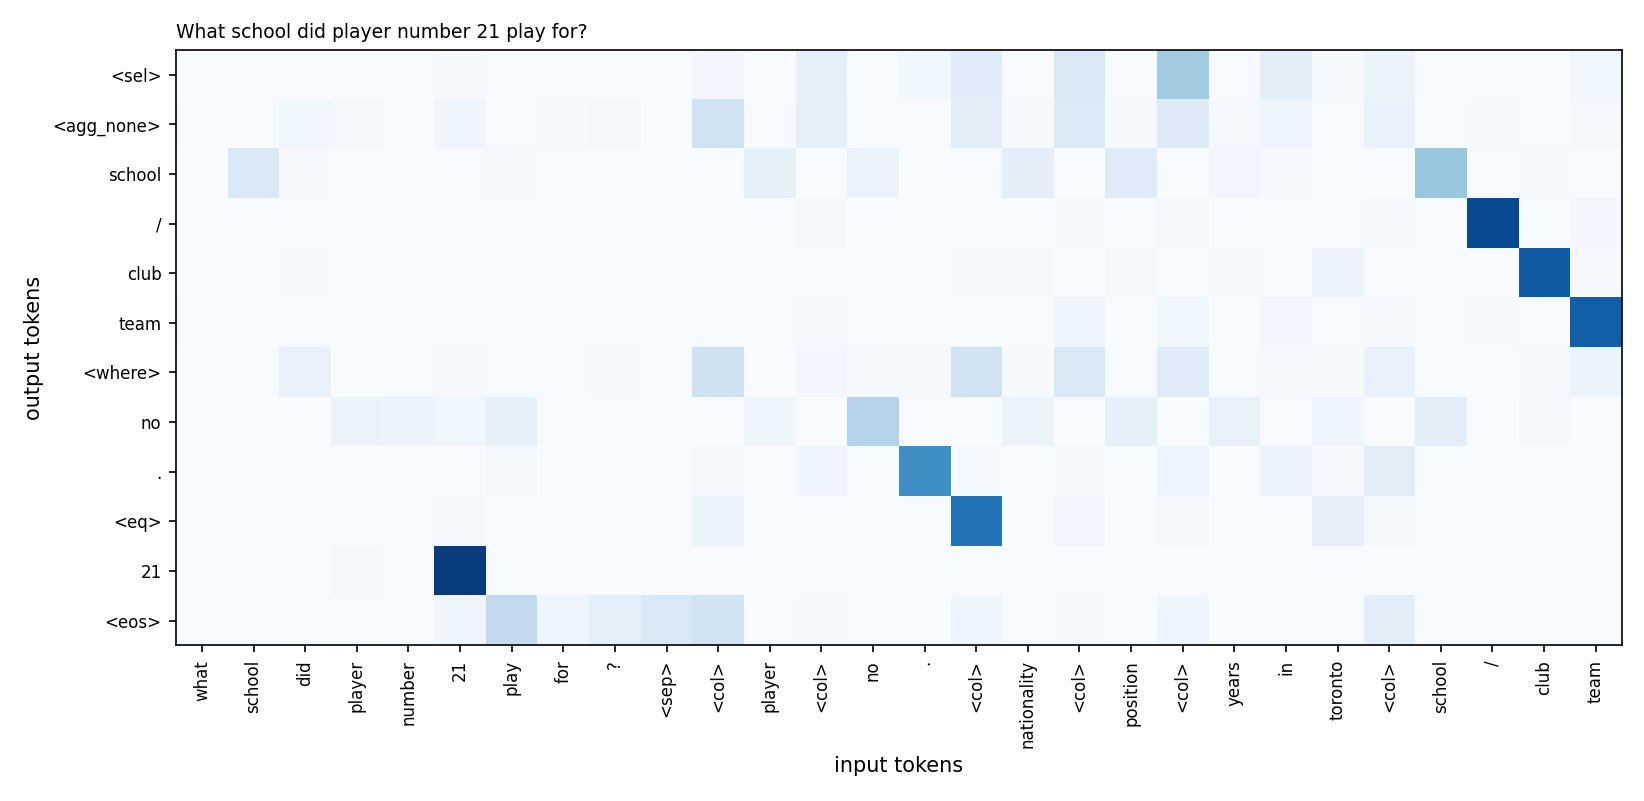






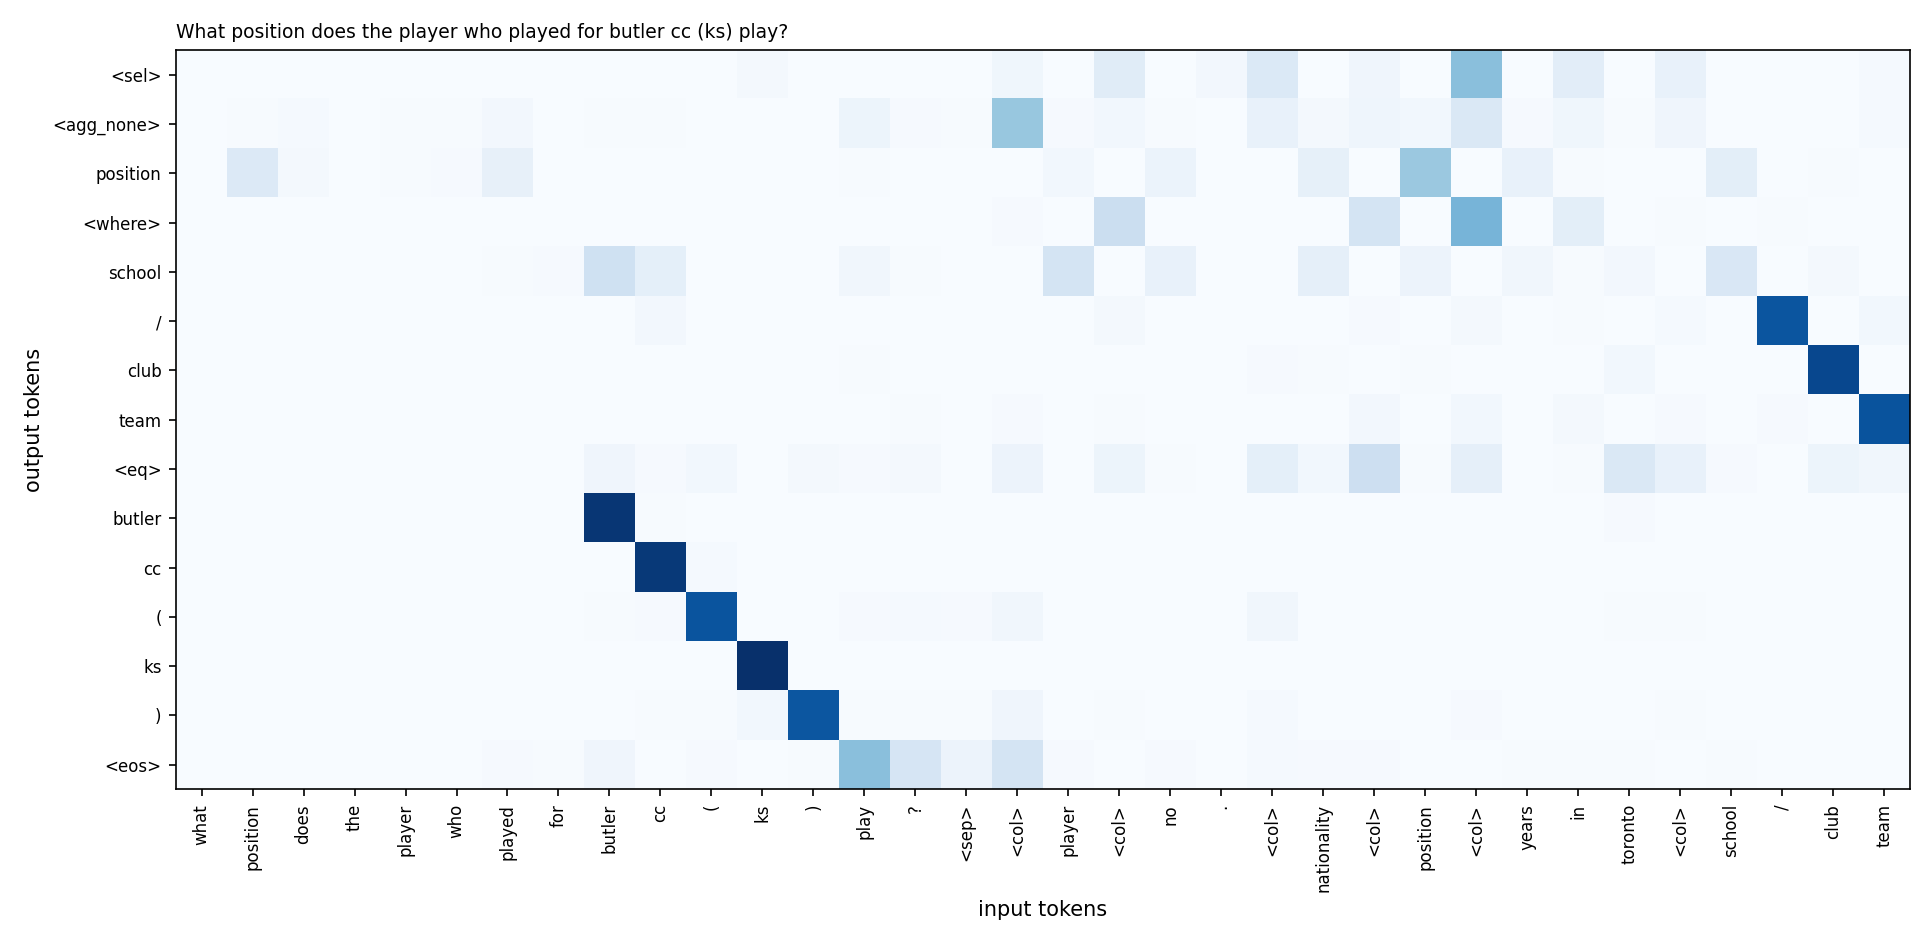

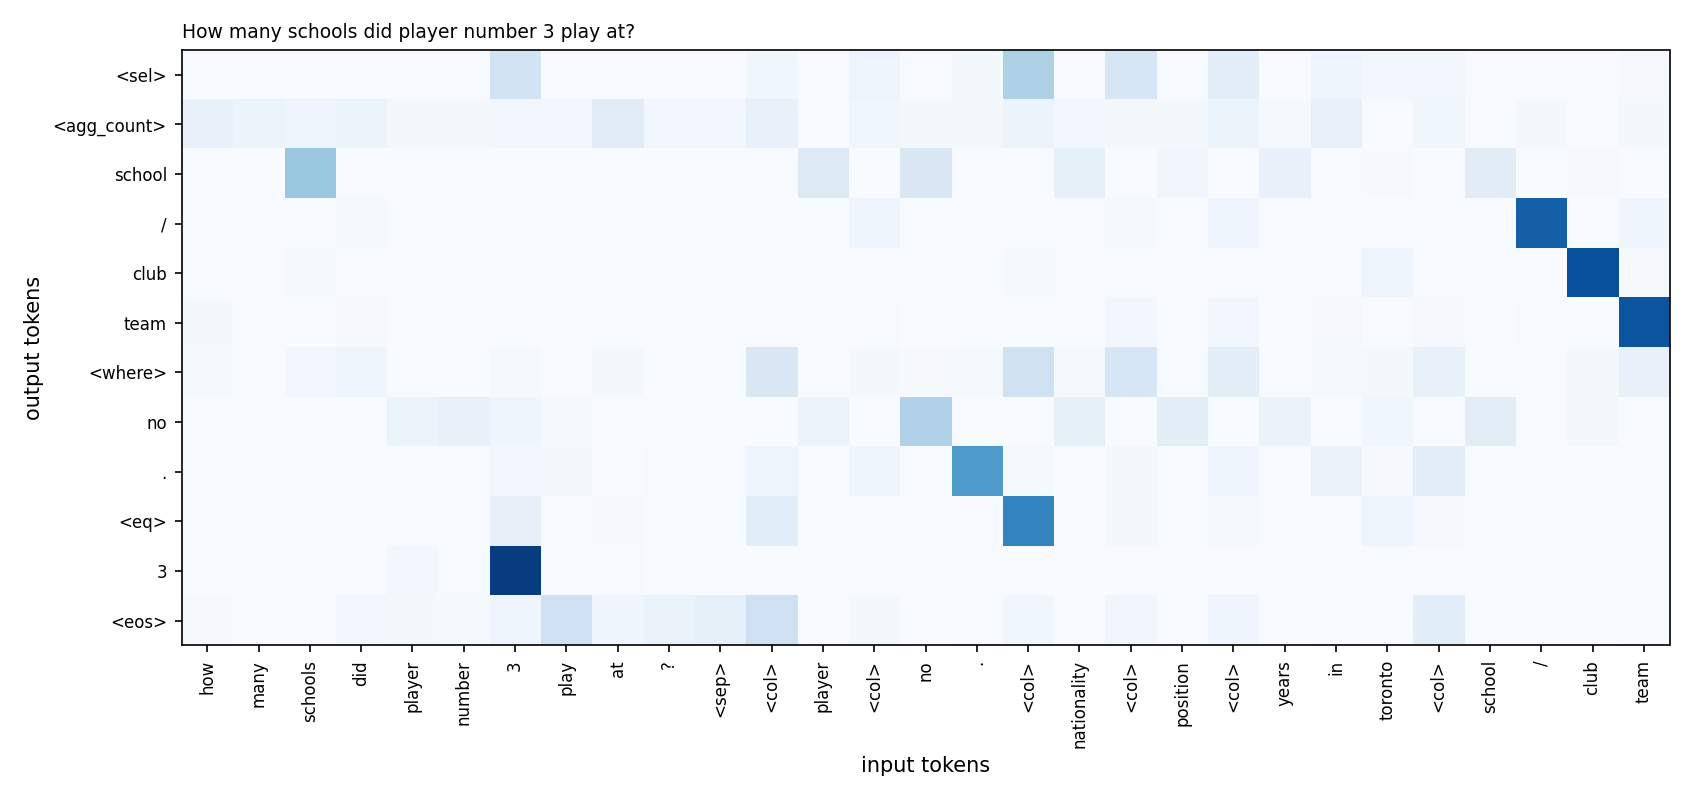

**What I observe.**

In the three heatmaps, the attention shows a clear **alignment** between the output and the input:

- **Column names are read from the list of columns.** When the decoder writes `school / club team` or `no .`, its attention moves along the same words in the part of the input that lists the columns (a diagonal: `school`, `/`, `club`, `team`). The word `school` also attracts a little attention on the question word `school` or `schools`, but the strongest cell is on the column name.
- **Values are read from the question.** The values `21`, `3` and `butler cc ( ks )` are written while the attention is almost entirely on the same words of the question (the darkest cells). For `butler cc ( ks )`, each of the five output words is aligned with its own word of the question.
- **The structure tokens have a spread-out attention.** `<sel>`, `<agg_none>`, `<agg_count>` and `<where>` look at many positions, mostly the `<col>` markers that separate the column names: the decoder looks over all the columns to decide which one to select. `<eq>` looks at the end of the column name that was just written (`.` in `no .`), and `<eos>` looks at the end of the question.

So the attention learned, without being told, to behave like a **pointer**: for the content of the query (column names and values), it points at the word to write. This explains the large gain of M2 over M1 and M1b, which had no way of looking back at the input. It also supports the idea of the next model (M3): the attention already points at the right word, and the copy mechanism turns this pointing into a probability for the word, even if it is not in the vocabulary.

## 6. Beam search

So far an output is generated greedily: at each step the best token is taken, and the decoder can never go back. **Beam search** keeps
the `k` best partial outputs (the *beams*) at each step, so a choice that looks slightly worse now can still win later.

**The idea.** The docstring describes the algorithm. With `beam_size = 1` it is exactly greedy decoding (a test checks this).

In [21]:
%%writefile {CODE}/src/t2s/decoding/beam.py
"""Beam search: keep the k best partial outputs at each step instead of only one.

Greedy decoding takes the best token at each step and can never go back. Beam search keeps
`beam_size` partial outputs ("beams") with their log-probabilities. At each step every beam
is extended with every token; the `beam_size` best extensions (over all beams) are kept.
An extension that writes <eos> is a finished output and is set aside. When enough outputs
are finished, the one with the best length-normalized score wins.

With beam_size = 1 this is exactly greedy decoding.
"""

import torch
import torch.nn.functional as F

from t2s.data.wikisql import Example




Writing /content/code/src/t2s/decoding/beam.py


**`_expand`** repeats, for each of the `k` beams, what the decoder needs from the input (all the beams read the same input).

In [22]:
%%writefile -a {CODE}/src/t2s/decoding/beam.py
def _expand(memory, k: int):
    """Repeat what the decoder needs from the input (batch size 1) for each of the k beams."""
    if isinstance(memory, torch.Tensor):
        return memory.expand(k, *memory.shape[1:]).contiguous()
    if isinstance(memory, tuple):
        return tuple(_expand(m, k) for m in memory)
    return memory  # None or a number: the same for all the beams




Appending to /content/code/src/t2s/decoding/beam.py


**`beam_search`: the start.** The function decodes one input. The state of the decoder is copied for the `k` beams. At the start there is
only one real beam (score 0); the other `k - 1` are empty slots with the score `-inf`. `finished` will hold the outputs that reached `<eos>`.

In [23]:
%%writefile -a {CODE}/src/t2s/decoding/beam.py
@torch.no_grad()
def beam_search(
    model,
    src: torch.Tensor,
    src_len: torch.Tensor,
    sos_id: int,
    eos_id: int,
    beam_size: int = 3,
    max_len: int = 64,
    length_penalty: float = 1.0,
) -> list[int]:
    """The best output for one input (src has shape (1, T)), without <sos> and <eos>.

    A finished output is scored by its log-probability divided by length ** length_penalty,
    so that long outputs are not punished only for being long.
    """
    model.eval()
    k = beam_size
    state, memory = model.init_decode(src, src_len)
    state = tuple(s.expand(-1, k, -1).contiguous() for s in state)  # (layers, k, H)
    memory = _expand(memory, k)

    tokens = torch.full((k,), sos_id, dtype=torch.long, device=src.device)
    scores = torch.full((k,), float("-inf"), device=src.device)
    scores[0] = 0.0  # at the start there is one real beam; the others are empty slots
    sequences: list[list[int]] = [[] for _ in range(k)]
    finished: list[tuple[float, list[int]]] = []



Appending to /content/code/src/t2s/decoding/beam.py


**One step for all the beams.** The decoder gives the scores of the next token for each beam; `log_softmax` turns them into
log-probabilities, which are added to the score of the beam. This gives the score of **every possible extension** of every beam (a table of
`k x V`). The `2k` best extensions over all beams are examined: one that writes `<eos>` is a **finished output** (its score is divided by its
length, so that long outputs are not punished only for being long); the others are kept as the new beams, until `k` are kept.

In [24]:
%%writefile -a {CODE}/src/t2s/decoding/beam.py
    for _ in range(max_len):
        logits, state = model.step(tokens, state, memory)
        total = scores[:, None] + F.log_softmax(logits, dim=-1)  # (k, V): score of every extension
        vocab_size = total.size(1)
        best_scores, best_index = total.view(-1).topk(min(2 * k, total.numel()))

        keep_beam, keep_token, keep_score = [], [], []
        for score, index in zip(best_scores.tolist(), best_index.tolist()):
            if score == float("-inf"):
                break
            beam, token = divmod(index, vocab_size)
            if token == eos_id:
                finished.append((score / (len(sequences[beam]) + 1) ** length_penalty, sequences[beam]))
            else:
                keep_beam.append(beam)
                keep_token.append(token)
                keep_score.append(score)
            if len(keep_beam) == k:
                break



Appending to /content/code/src/t2s/decoding/beam.py


**Stopping and preparing the next step.** The search stops when there are enough finished outputs **and** no unfinished beam can beat the
best finished one. (A first version stopped as soon as `k` outputs were finished, and a test showed that poor outputs found early could stop the
search before the correct, longer output was finished.) Otherwise the states of the kept beams are reordered (`s[:, order]`) and the next step
starts from their last tokens.

In [25]:
%%writefile -a {CODE}/src/t2s/decoding/beam.py
        if not keep_beam:
            break
        extended = [sequences[b] + [t] for b, t in zip(keep_beam, keep_token)]

        # Stop when there are enough finished outputs and the best unfinished one is no
        # better than the best finished one (finished outputs with a poor score, found
        # early, must not stop the search before a better output can finish).
        if len(finished) >= k:
            best_finished = max(score for score, _ in finished)
            best_unfinished = max(s / len(seq) ** length_penalty for s, seq in zip(keep_score, extended))
            if best_unfinished <= best_finished:
                break

        # Continue with the kept extensions; empty slots keep the score -inf.
        sequences = extended + [[] for _ in range(k - len(extended))]
        order = torch.tensor(keep_beam + [0] * (k - len(keep_beam)), device=src.device)
        state = tuple(s[:, order] for s in state)
        tokens = torch.tensor(keep_token + [sos_id] * (k - len(keep_token)), device=src.device)
        scores = torch.tensor(keep_score + [float("-inf")] * (k - len(keep_score)), device=src.device)



Appending to /content/code/src/t2s/decoding/beam.py


**The result.** If no beam reached `<eos>` within `max_len` steps, the unfinished beams are used. The best output by normalized score is returned.

In [26]:
%%writefile -a {CODE}/src/t2s/decoding/beam.py
    if not finished:  # no output reached <eos> within max_len: use the unfinished beams
        for seq, score in zip(sequences, scores.tolist()):
            if score > float("-inf"):
                finished.append((score / (len(seq) + 1) ** length_penalty, seq))
    return max(finished, key=lambda item: item[0])[1]




Appending to /content/code/src/t2s/decoding/beam.py


**`beam_decode_examples`** runs beam search for every example, one at a time, and returns the output tokens.

In [27]:
%%writefile -a {CODE}/src/t2s/decoding/beam.py
def beam_decode_examples(
    model,
    examples: list[Example],
    codec,
    device,
    beam_size: int = 3,
    max_src_len: int = 128,
    max_tgt_len: int = 64,
    length_penalty: float = 1.0,
) -> list[list[str]]:
    """Beam search for every example (one at a time). Returns the output tokens."""
    vocab = codec.vocab
    outputs = []
    for ex in examples:
        encoded = codec.encode(ex, max_src_len, max_tgt_len)
        src = torch.tensor([encoded.src], device=device)
        src_len = torch.tensor([len(encoded.src)], device=device)
        ids = beam_search(
            model, src, src_len, vocab.sos_id, vocab.eos_id, beam_size, max_tgt_len, length_penalty
        )
        outputs.append(codec.decode(ids, encoded))
    return outputs


Appending to /content/code/src/t2s/decoding/beam.py


In [28]:
import time
from t2s.decoding.beam import beam_decode_examples
from t2s.evaluate import decode_examples
from t2s.eval.metrics import score

subset = splits["dev"][:1000]    # a subset of dev, because beam search is slower
rows = []

started = time.time()
greedy_outputs = decode_examples(model, subset, codec, device)
metrics, _ = score(subset, greedy_outputs, dev_executor)
rows.append({"decoding": "greedy", "exact match": metrics["exact_match"], "execution accuracy": metrics["execution_accuracy"],
             "seconds": round(time.time() - started)})

for k in (1, 3, 5):
    started = time.time()
    outputs = beam_decode_examples(model, subset, codec, device, beam_size=k)
    metrics, _ = score(subset, outputs, dev_executor)
    rows.append({"decoding": f"beam, k = {k}", "exact match": metrics["exact_match"], "execution accuracy": metrics["execution_accuracy"],
                 "seconds": round(time.time() - started)})
    if k == 1:
        same = sum(a == b for a, b in zip(greedy_outputs, outputs))
        print(f"beam search with k = 1 gives the same output as greedy decoding for {same} of {len(subset)} questions")

beam_table = pd.DataFrame(rows).set_index("decoding").round(4)
beam_table.to_csv("results/phase4_attention/beam_search.csv")
beam_table

beam search with k = 1 gives the same output as greedy decoding for 1000 of 1000 questions


,exact match,execution accuracy,seconds
decoding,,,
greedy,0.347,0.373,0
"beam, k = 1",0.347,0.373,18
"beam, k = 3",0.344,0.372,18
"beam, k = 5",0.344,0.372,18


**What I observe.**

- **The implementation is correct.** With a beam of size 1, beam search gives exactly the same output as greedy decoding for the 1,000 of 1,000 questions.
- **Beam search does not improve the results.** With k = 3 and k = 5 the exact match is 34.4%, against 34.7% for greedy decoding, and the execution accuracy is 37.2%, against 37.3%. The difference (3 questions out of 1,000 for the exact match) is within the noise. A larger beam does not change the result between k = 3 and k = 5.
- **Why.** Beam search helps when the model assigns the highest probability to the right query but greedy decoding misses it because of a locally wrong choice. Here the model is very confident at each step (the perplexity is 1.43), so the best token at each step is almost always part of the best query, and the beam finds the same query. The mistakes of the model come from what it does not know (new words, wrong columns), not from the search, so a better search cannot fix them.
- **Cost.** My beam search decodes one question at a time and takes 18 seconds for 1,000 questions, while the batched greedy decoding takes less than a second. Since it brings no gain, I use **greedy decoding** for all the final results.
- These numbers are measured on the first 1,000 questions of the dev set, so they are lower than the 40.2% on the full dev set.

## 7. Summary of this notebook

**What I built:** the attention layer, a decoder that uses it, the model M2, a decoding function that returns the attention weights, and beam
search.

**Checks:** the weights add up to 1 and the padding gets a weight of exactly 0; the first loss is the expected `ln(V)`; the model can memorize a
batch; beam search with `k = 1` equals greedy decoding.

**Next notebook:** `05_copy_and_bpe.ipynb` addresses the biggest limit found in notebook 02: the words that the model has never seen.